# Music Genre Classification & Movie Clustering<br>
***
## 1. Introduction
In this notebook, I am going to conduct predictive analytics, by building predictive models on a dataset using Python in the Jupyter Notebook environment. It covers how to read and describe the data using basic statistics, split the dataset into training and testing, conduct multi-class classification using Support Vector Machine (SVM), evaluate and compare predictive models, explore different datasets and select a particular dataset that meets certain criteria, deal with missing data, and conduct clustering using k-means.

The report's rough outline is as follows:
1. Introduction
2. Supervised Learning
2. Classification (training)
3. Classification (prediction)
4. Independent Evaluation
5. Selection of Dataset & Clustering
6. Conclusion
7. References

***
## Part A: Classification
### A1. Supervised Learning
#### A1.1:
##### Answer:
Supervised machine learning is a type of machine learning where the model is trained on a dataset. All the data are labelled and the algorithms learn to predict the output from the input data. The goal of supervised machine learning is to approximate the mapping function so well that when you have new input data (x), you can predict the output variable (y) for that data. Some examples of supervised learning include classification (the output variable is a category) and regression (the output variable is a real value). Moreover, examples of supervised machine learning algorithms include linear regression, decision trees, random forests, and support vector machines (SVM).

Labelled data is data that has a label such as name, number, or type. For example, an image that is a cat or dog. Labelled data is used to train machine learning models in supervised learning, whereas unlabelled data is used in unsupervised learning. Next, labelled data is hard to obtain, whereas unlabelled data is relatively easy to get. Labelled data can be used to find useful insights, whereas unlabelled data is used in unsupervised learning methods that can help discover new clusters of data, allowing for new categorizations when labeling.

Train datasets are used in training predictive models. The models can then be applied to make predictions on new instances.

Test datasets are used to evaluate predictive models based on how well they predict the labels for test instances which are not used in training predictive models.

#### A1.2:
##### Code:

In [1]:
# Import library
import pandas as pd

# Read the 'music_genre_train.csv' file
df = pd.read_csv('music_genre_train.csv')

In [2]:
df.head()

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,music_genre
0,77382,Sheena Ringo,獣ゆく細道,48,0.01340,0.423,224053,0.799,0.000004,0.1470,-4.227,0.0447,124.626,0.5560,1
1,23554,empty_field,Fossil Roo,22,0.86200,0.590,151067,0.221,0.468000,0.0736,-16.338,0.0383,129.984,0.0331,1
2,82886,The Beatles,Dear Prudence - 2018 Mix,62,0.09040,0.395,234973,0.538,0.000453,0.0685,-10.300,0.0456,150.785,0.3690,9
3,37772,Pink Floyd,Have a Cigar,64,0.40700,0.454,307733,0.650,0.049800,0.5890,-10.191,0.0437,120.154,0.7200,9
4,80191,A-Trak,Push,43,0.00145,0.642,213512,0.877,0.002790,0.0984,-2.878,0.0450,126.058,0.4960,5


In [3]:
df.tail()

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,music_genre
25953,70328,Tosca,Swimswimswim,57,0.01400,0.903,252245,0.545,0.00492,0.224,-7.761,0.0380,120.017,0.956,5
25954,65621,Wolfgang Amadeus Mozart,"Requiem in D Minor, K. 626: II. Kyrie eleison ...",13,0.99300,0.275,179240,0.409,0.82500,0.215,-16.666,0.0322,77.858,0.225,3
25955,82975,Elmore James,Dust My Broom,43,0.01150,0.507,175040,0.660,0.33600,0.322,-4.957,0.0306,100.783,0.696,2
25956,36145,Wiz Khalifa,True Colors (feat. Nicki Minaj),50,0.00451,0.805,255147,0.744,0.00000,0.350,-6.020,0.0572,124.983,0.519,6
25957,48372,Dreezy,Chanel Slides (feat. Kash Doll),59,0.00570,0.809,174177,0.535,0.00000,0.301,-6.186,0.0580,146.224,0.226,8


In [4]:
df.shape

(25958, 15)

In [5]:
# Separate the features and the label
X = df.iloc[:, 3:-1].values # Features
y = df.iloc[:, -1].values # Label - 'music_genre'

In [6]:
X[25953:25958] # Input / Features

array([[ 5.70000e+01,  1.40000e-02,  9.03000e-01,  2.52245e+05,
         5.45000e-01,  4.92000e-03,  2.24000e-01, -7.76100e+00,
         3.80000e-02,  1.20017e+02,  9.56000e-01],
       [ 1.30000e+01,  9.93000e-01,  2.75000e-01,  1.79240e+05,
         4.09000e-01,  8.25000e-01,  2.15000e-01, -1.66660e+01,
         3.22000e-02,  7.78580e+01,  2.25000e-01],
       [ 4.30000e+01,  1.15000e-02,  5.07000e-01,  1.75040e+05,
         6.60000e-01,  3.36000e-01,  3.22000e-01, -4.95700e+00,
         3.06000e-02,  1.00783e+02,  6.96000e-01],
       [ 5.00000e+01,  4.51000e-03,  8.05000e-01,  2.55147e+05,
         7.44000e-01,  0.00000e+00,  3.50000e-01, -6.02000e+00,
         5.72000e-02,  1.24983e+02,  5.19000e-01],
       [ 5.90000e+01,  5.70000e-03,  8.09000e-01,  1.74177e+05,
         5.35000e-01,  0.00000e+00,  3.01000e-01, -6.18600e+00,
         5.80000e-02,  1.46224e+02,  2.26000e-01]])

In [7]:
y[25953:25958] # Output / Label

array([5, 3, 2, 6, 8], dtype=int64)

#### A1.3:
##### Code:

In [8]:
# Split the data for training and testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

### A2. Classification (training)
#### A2.1:
##### Answer:

Binary classification is a type of supervised machine learning classification that classifies data into two mutually exclusive groups or categories. For example, it can be either 0 or 1, true or false, spam or not spam, etc. Binary classification algorithms include Support Vector Machines (SVM), Decision Trees, K-Nearest Neighbor, etc. Applications of binary classification include spam email detection, fraud detection, and medical diagnosis.<br><br>On the other hand, multi-class classification is a type of supervised machine learning classification that classifies data into more than two groups or categories. For example, a multi-class classifier can classify images of animals into different categories such as cats, dogs, and mice. An example of multi-class classification algorithm is Random Forest.<br><br>The main differences between binary and multi-class classification is the number of classes in the output variable. In binary classification, there are only two classes, whereas in multi-class classification, there are more than two classes.

#### A2.2.a:
##### Answer:
Since the range of values of raw data varies widely, in some machine learning algorithms, objective functions will not work properly without feature scaling (aka normalization). For example, many classifiers calculate the distance between two points by the Euclidean distance. If one of the features has a broad range of values, the distance will be governed by this particular feature. Therefore, the range of all features should be normalized so that each feature contributes approximately proportionately to the final distance. In addition, our motivation here is to visualise the feature space later on.

#### A2.2.b:
##### Code:

In [9]:
# Scale the data properly by using the appropriate normalisation function
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

# Apply fit_transform() to the training dataset to scale it to have a mean of 0
# and a certain standard deviation. These values will be stored in sc, which is the StandardScaler object
X_train = sc.fit_transform(X_train)
# Apply to the testing dataset using transform() to scale it the same way
X_test = sc.transform(X_test)

#### A2.3.a:
##### Answer:
Support Vector Machines (SVMs) are a set of supervised learning methods used for classification, regression and outliers detection. The Support Vector Machine algorithm classifies data by finding the best line or hyperplane that maximizes the distance between each class and best divides a dataset into two classes in an N-dimensional space. The hyperplane is the decision boundary that separates the classes in the feature space. The goal of the SVM is to create the best line/hyperplane that can segregate n-dimensional space into classes so that we can easily insert new data point in the correct category in the future. The data points that are closest to the hyperplane are called support vectors. The hyperplane is defined by the support vectors. SVM is a binary classifier, but it can be extended to multi-class classification using one-vs-one or one-vs-all strategies.

#### A2.3.b:
##### Answer:
The SVM kernel is a function that takes low-dimensional input space and transforms it into a higher-dimensional space. It is used to transform the input data into the required form. In other words, it transforms the linearly inseparable data into linearly separable data. The goal of SVM kernel is to solve non-linear classification problems and let us classify the data easier by implicitly mapping the input data to a higher-dimensional feature space.

#### A2.3.c:
##### Code:

In [10]:
# Build a predictive SVM model using the trainig dataset
from sklearn.svm import SVC
svc = SVC(
    C=8,
    random_state=0
)
svc.fit(X_train, y_train)

SVC(C=8, random_state=0)

#### A2.4:
##### Code:

In [11]:
# Repeat the process by using Random Forest algorithm instead of SVM
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(
    n_estimators=99,
    criterion='gini',
    min_samples_split=10,
    min_samples_leaf=8,
    random_state=0,
)
rfc.fit(X_train, y_train)

RandomForestClassifier(min_samples_leaf=8, min_samples_split=10,
                       n_estimators=99, random_state=0)

### A3. Classification (prediction)
#### A3.1:
##### Code:

In [12]:
# Conduct the prediction for the 'music_genre' (label) using the two models built by SVM and Random Forest using the testing dataset above
y_pred_svm = svc.predict(X_test)
y_pred_rfc = rfc.predict(X_test)

#### A3.2:
##### Code:

In [13]:
# Making the confusion matrix for the SVM model
from sklearn.metrics import confusion_matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_svm

array([[247,   9,  10,   1, 112,  33,  66,  30,  22, 128],
       [ 17, 495,  44,  31,  15,  25,   0,   8,   0,   4],
       [ 37,  84, 349,  11,  74,  29,   1,  65,   1,  26],
       [ 18,  27,  17, 563,   4,   7,   0,  26,   0,   7],
       [ 45,  12,  40,   2, 359,  13,  14,  42,  10, 101],
       [ 37,  30,  37,  10,  39, 372,  18,  59,   6,  23],
       [ 32,   1,   1,   0,   9,   4, 324,   6, 223,  39],
       [ 37,  11,  80,  43,  40,  90,  17, 327,   3,  27],
       [ 28,   0,   0,   0,   5,   0, 281,   6, 225,  87],
       [ 61,   0,   1,   2,  37,   3,  25,  10,  35, 458]], dtype=int64)

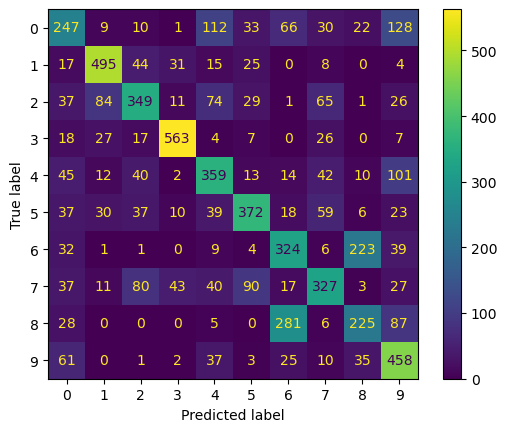

In [14]:
# Display the confusion matrix for the SVM model
from sklearn.metrics import ConfusionMatrixDisplay
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
disp_svm.plot()

In [15]:
# Making the confusion matrix for the Random Forest model
cm_rfc = confusion_matrix(y_test, y_pred_rfc)
cm_rfc

array([[209,   6,  17,   0,  90,  38,  62,  40,  25, 171],
       [ 17, 486,  37,  49,  14,  22,   0,   9,   0,   5],
       [ 42,  65, 336,  13,  68,  45,   4,  72,   0,  32],
       [ 19,  21,  14, 561,   4,  16,   0,  27,   0,   7],
       [ 30,  11,  30,   2, 380,   4,  13,  39,  10, 119],
       [ 33,  33,  51,   7,  26, 367,  10,  63,  10,  31],
       [ 12,   0,   0,   0,   4,   3, 341,   5, 230,  44],
       [ 25,  10,  82,  55,  33,  92,  15, 323,   4,  36],
       [ 14,   0,   0,   0,   5,   3, 316,   4, 198,  92],
       [ 42,   0,   0,   4,  28,   3,  35,  11,  41, 468]], dtype=int64)

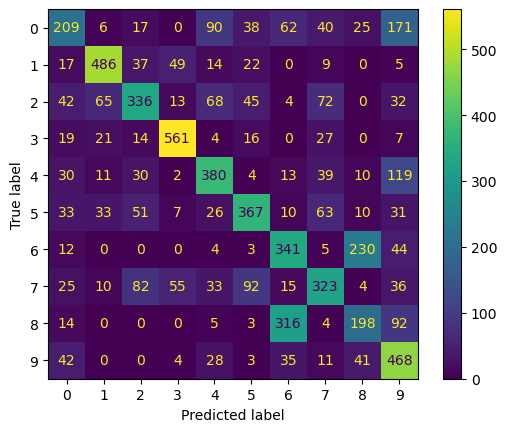

In [16]:
# Display the confusion matrix for the Random Forest model
disp_rfc = ConfusionMatrixDisplay(confusion_matrix=cm_rfc, display_labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
disp_rfc.plot()

#### A3.3:
##### Code:

In [17]:
# Evaluate the performance of SVM
from sklearn.metrics import accuracy_score, recall_score, precision_score
accuracy = accuracy_score(y_test, y_pred_svm)
sensitivity = recall_score(y_test, y_pred_svm, average='macro')
precision = precision_score(y_test, y_pred_svm, average='macro')
print(f"Accuracy: {accuracy}")
print(f"Sensitivity: {sensitivity}")
print(f"Precision: {precision}")

Accuracy: 0.5730354391371341
Sensitivity: 0.5731511224065182
Precision: 0.5733372511911871


In [18]:
# Evaluate the performance of Random Forest
accuracy = accuracy_score(y_test, y_pred_rfc)
sensitivity = recall_score(y_test, y_pred_rfc, average='macro')
precision = precision_score(y_test, y_pred_rfc, average='macro')
print(f"Accuracy: {accuracy}")
print(f"Sensitivity: {sensitivity}")
print(f"Precision: {precision}")

Accuracy: 0.565331278890601
Sensitivity: 0.565625489614149
Precision: 0.5667930201577047


##### Answer:
The performance of SVM and Random Forest can be compared using the accuracy, sensitivity, and precision. The model with the highest accuracy, sensitivity, and precision is considered the better model. In this case, the SVM model performed better than the Random Forest model. The SVM model had higher accuracy, sensitivity, and precision compared to the Random Forest model. The SVM model had an accuracy of 0.573, sensitivity of 0.573, and precision of 0.573, whereas the Random Forest model had an accuracy of 0.565, sensitivity of 0.566, and precision of 0.567. Hence, the SVM model performed better in this case.

### A4. Independent evaluation
#### A4.1:
##### Code:

In [19]:
# Read the 'music_genre_unlabelled.csv' file
df2 = pd.read_csv('music_genre_unlabelled.csv')

# Scale the data properly
x_test = sc.transform(df2.iloc[:, 3:].values)

# Use the best model built earlier to predict the 'music_genre' for the songs in this file, in this case the SVM model
y_pred = svc.predict(x_test)

#### A4.2a:
##### Code:

In [20]:
# Read the submission file
df3 = pd.read_csv('predictions_v1.csv')

# Update the 'music_genre' column with the predicted values
df3['music_genre'] = y_pred

# Write the DataFrame back to the CSV file
df3.to_csv('predictions_v1.csv', index=False)

***
## Part B: Selection of Dataset, Clustering
### B1. Selection of a Dataset with missing data, Clustering
#### B1.1:

Direct link to the public dataset from the internet: https://www.kaggle.com/datasets/prishasawhney/imdb-dataset-top-2000-movies

#### B1.2:
##### Code:

In [21]:
# Import the libraries
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
%matplotlib inline

# Load the dataset
df4 = pd.read_csv('imdb_top_2000_movies.csv')

In [22]:
df4.head()

,Movie Name,Release Year,Duration,IMDB Rating,Metascore,Votes,Genre,Director,Cast,Gross
0,The Godfather,1972,175,9.2,100.0,"2,002,655","Crime, Drama",Francis Ford Coppola,Marlon Brando,$134.97M
1,The Godfather Part II,1974,202,9.0,90.0,"1,358,608","Crime, Drama",Francis Ford Coppola,Al Pacino,$57.30M
2,Ordinary People,1980,124,7.7,86.0,"56,476",Drama,Robert Redford,Donald Sutherland,$54.80M
3,Lawrence of Arabia,1962,218,8.3,100.0,"313,044","Adventure, Biography, Drama",David Lean,Peter O'Toole,$44.82M
4,Straw Dogs,1971,113,7.4,73.0,"64,331","Crime, Drama, Thriller",Sam Peckinpah,Dustin Hoffman,NaN


In [23]:
# Check the dataset dimension
df4.shape

(2000, 10)

In [24]:
# Remove rows with missing data
df4.dropna(inplace=True)

In [25]:
df4.head()

,Movie Name,Release Year,Duration,IMDB Rating,Metascore,Votes,Genre,Director,Cast,Gross
0,The Godfather,1972,175,9.2,100.0,"2,002,655","Crime, Drama",Francis Ford Coppola,Marlon Brando,$134.97M
1,The Godfather Part II,1974,202,9.0,90.0,"1,358,608","Crime, Drama",Francis Ford Coppola,Al Pacino,$57.30M
2,Ordinary People,1980,124,7.7,86.0,"56,476",Drama,Robert Redford,Donald Sutherland,$54.80M
3,Lawrence of Arabia,1962,218,8.3,100.0,"313,044","Adventure, Biography, Drama",David Lean,Peter O'Toole,$44.82M
5,Close Encounters of the Third Kind,1977,138,7.6,90.0,"216,050","Drama, Sci-Fi",Steven Spielberg,Richard Dreyfuss,$132.09M


In [26]:
df4.shape

(1870, 10)

In [27]:
# Remove unwanted characters in the 'Gross' column and convert the strings to floats
df4['Gross'] = df4['Gross'].str[1:-1].astype(float)

In [28]:
# Perform k-means clustering using only two numerical features from the dataset,
# and apply k-means clustering to the data to create k clusters, where k = 4
kmeans = KMeans(n_clusters=4).fit(
    df4[['IMDB Rating', 'Gross']]
)

#### B1.3:
##### Code:

Text(0, 0.5, 'Gross ($) in Million')

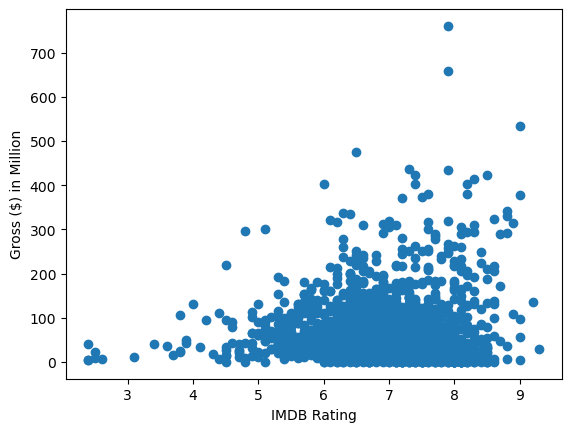

In [29]:
# Visualise the data
plt.scatter(df4['IMDB Rating'], df4['Gross'])
plt.xlabel('IMDB Rating')
plt.ylabel('Gross ($) in Million')

In [30]:
# Look at the outputs: Two cluster centers
kmeans.cluster_centers_

array([[  6.77888514,  74.05184122],
       [  6.94708171, 159.57066148],
       [  6.955683  ,  20.66499479],
       [  7.53387097, 334.33451613]])

In [31]:
# Look at the outputs: Cluster labels
kmeans.labels_

array([1, 0, 0, ..., 2, 2, 2])

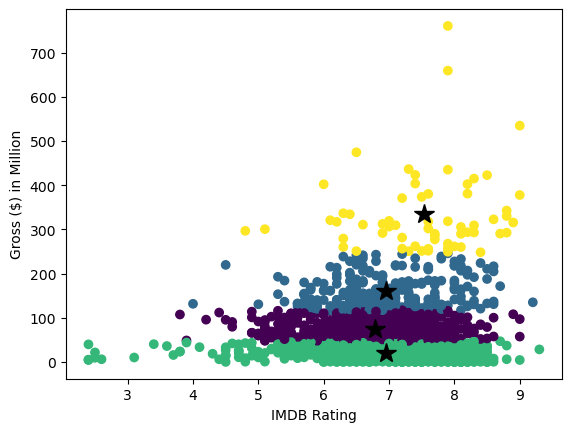

In [32]:
# Visualise the output labels
plt.scatter(
    x=df4['IMDB Rating'],
    y=df4['Gross'],
    c=kmeans.labels_
)

# Visualise the cluster centers (black stars)
plt.plot(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    'k*',
    markersize=15
)

plt.xlabel('IMDB Rating')
plt.ylabel('Gross ($) in Million')
plt.show()

##### Answer:
- The subgroup in yellow are mostly movies that have very high IMDB rating. These movies mostly have higher gross than the ones in the other clusters, and this might be due to their high IMDB rating by the audience. Thus, we can see that a good movie rating leads to a higher gross profit.

- The subgroup in blue are mostly movies that also have a high IMDB rating by the audience. However, the average IMDB rating for these movies are slightly lower than the movies in the yellow cluster. Moreover, these movies also have a lower gross compared to the movies in the yellow cluster. This might be due to the fact that these movies are not as good and popular as the ones in the yellow cluster.

- The subgroup in purple are movies that have a decent IMDB rating in average. These movies have a lower gross compared to the movies in the yellow and blue clusters. This might be due to the fact that these movies are not as popular as the ones in the yellow and blue clusters.

- The subgroup in green are movies that have the lowest average IMDB rating among all other clusters. These movies have the lowest gross compared to the movies in the other clusters. This might be due to the fact that these movies are not popular and not well-received by the audience, as we can see that some movies have a very bad IMDB rating, which is less than 3.0.

***
## Conclusion:
To sum up, I have learnt how to conduct predictive analytics using Python in the Jupyter Notebook environment. The process of conducting predictive analytics involves several steps such as data preprocessing, data cleaning, data wrangling, model training, model evaluation, and model selection. Furthermore, I have also learnt how to use different machine learning algorithms such as SVM and Random Forest for classification tasks. Last but not least, I have also learnt how to use clustering algorithms such as k-means for clustering tasks. Overall, I have gained a valuable experience in conducting predictive analytics using Python in this project.

***
## References:
https://www.ibm.com/topics/support-vector-machine<br>
https://www.javatpoint.com/machine-learning-support-vector-machine-algorithma<br>
https://scikit-learn.org/stable/modules/svm.html?msclkid=75f08c50b63f11ec9a3ba40f3dfd21d3#<br>
https://www.techtarget.com/whatis/definition/support-vector-machine-SVM<br>
https://www.analyticsvidhya.com/blog/2017/09/understaing-support-vector-machine-example-code/<br>
https://www.ibm.com/topics/data-labeling<br>
https://www.javatpoint.com/data-labelling-in-machine-learning<br>
***